# 02 - Whole-image model

This notebook trains a model that looks at each whole pill image and learns what a normal pill looks like. It will later be compared with the patch model.

## Steps

1. Load the shared split from `split.csv`. Use it only after notebook 01 has filled in the real image rows.
2. Resize each whole color image to 256 × 256. If the pixel values are rescaled, calculate that rescaling from the training images only.
3. Build a convolutional autoencoder that learns to rebuild a normal pill image.
4. Train on the normal training images only. Use the validation images to watch the reconstruction error, not to update the weights.
5. Check how well the model rebuilds the normal validation images.
6. Save the trained weights in `outputs/checkpoints/`.
7. Plot the training and validation error and save the figure in `outputs/figures/`.
8. Do not read test labels or defect masks. Notebook 04 will score this model in the same way as the patch model.


### 02 - Whole-Image Autoencoder

This notebook builds and trains a convolutional autoencoder to detect potential defects in pill images.

The model will learn what normal pills look like by training only on normal pill images. It will then reconstruct images and use reconstruction error to measure how different the output is from the original image.

The whole-image model will later be compared with the patch-based model.

### Objectives

1. Load the shared training and validation split.
2. Prepare and resize the pill images.
3. Build a convolutional autoencoder.
4. Train the model using normal pill images only.
5. Evaluate reconstruction performance on normal validation images.
6. Save the trained model and training results.


### 1. Import Libraries and Set Up Paths

Import the libraries needed for image processing, data preparation, model development, and visualization.

Set up the project paths for the dataset, shared split file, saved model checkpoints, and output figures.

In [1]:
# Import libraries
from pathlib import Path
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import transforms

# Find the project folder
PROJECT_DIR = Path.cwd()

if not (PROJECT_DIR / "split.csv").exists():
    PROJECT_DIR = PROJECT_DIR.parent

# Set folder locations
DATA_DIR = PROJECT_DIR / "data" / "pill"
SPLIT_FILE = PROJECT_DIR / "split.csv"

OUTPUT_DIR = PROJECT_DIR / "outputs"
CHECKPOINT_DIR = OUTPUT_DIR / "checkpoints"
FIGURE_DIR = OUTPUT_DIR / "figures"

# Create output folders
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

# Use Mac GPU if available
if torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

print("Project folder:", PROJECT_DIR)
print("Dataset found:", DATA_DIR.exists())
print("Split file found:", SPLIT_FILE.exists())
print("Device:", device)

Project folder: /Users/morgancook/Documents/SYRACUSE UNIVERSITY/Fall 2026/IST 691/FinalProject_Pills/pill-defect-detection
Dataset found: True
Split file found: True
Device: mps


### 2. Load the Shared Data Split

Load the shared split.csv file created in notebook 01.

The 267 normal training images are divided into:
- 214 training images
- 53 validation images

Only normal pill images will be used in this notebook. The official test images and defect masks will not be used during training.

In [2]:
# Load the shared data split
split_df = pd.read_csv(SPLIT_FILE)

# Separate training and validation paths
train_paths = split_df[split_df["split"] == "train"]["relative_path"].tolist()
val_paths = split_df[split_df["split"] == "val"]["relative_path"].tolist()

# Check the number of images
print("Training images:", len(train_paths))
print("Validation images:", len(val_paths))

Training images: 214
Validation images: 53


### 3. Prepare the Images

Prepare the pill images for the autoencoder.

- Resize images to 256 × 256 pixels.
- Keep images in RGB color format.
- Convert images into PyTorch tensors.
- Scale pixel values to the range 0–1.

The images will be loaded into PyTorch tensors and organized into batches using DataLoaders.

In [3]:
# Resize images and convert them to tensors
transform = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.ToTensor()
])

# Load training images
train_images = []

for path in train_paths:
    image = Image.open(DATA_DIR / path).convert("RGB")
    train_images.append(transform(image))

# Load validation images
val_images = []

for path in val_paths:
    image = Image.open(DATA_DIR / path).convert("RGB")
    val_images.append(transform(image))

# Combine images into tensors
train_images = torch.stack(train_images)
val_images = torch.stack(val_images)

print("Training image shape:", train_images.shape)
print("Validation image shape:", val_images.shape)

Training image shape: torch.Size([214, 3, 256, 256])
Validation image shape: torch.Size([53, 3, 256, 256])


### 4. Create DataLoaders

Create training and validation DataLoaders to organize the images into batches.

The training DataLoader will shuffle the images, while the validation DataLoader will keep them in order.

A batch size of 16 will be used.

In [4]:
#Set barch size
batch_size = 16

# Create Validation DataLoaders
val_loader = DataLoader(val_images, batch_size=batch_size, shuffle=False)

print("Validation DataLoader created successfully.")

Validation DataLoader created successfully.


### 5. Build the Convolutional Autoencoder

Build a convolutional autoencoder with two main components.

**Encoder:** Uses convolutional layers to compress the input image into a smaller representation.

**Decoder:** Uses transposed convolutional layers to reconstruct the original image from the compressed representation.

The model takes a 256 × 256 RGB image and attempts to recreate it.

In [7]:
class ConvAutoencoder(nn.Module):

    def __init__(self):
        super().__init__()

        # Encoder: compress the image
        self.encoder = nn.Sequential(

            nn.Conv2d(3, 32, kernel_size=3, stride=2, padding=1),
            nn.ReLU(),

            nn.Conv2d(32, 64, kernel_size=3, stride=2, padding=1),
            nn.ReLU(),

            nn.Conv2d(64, 128, kernel_size=3, stride=2, padding=1),
            nn.ReLU(),

            nn.Conv2d(128, 256, kernel_size=3, stride=2, padding=1),
            nn.ReLU()
        )

        # Decoder: reconstruct the image
        self.decoder = nn.Sequential(

            nn.ConvTranspose2d(256, 128, kernel_size=4, stride=2, padding=1),
            nn.ReLU(),

            nn.ConvTranspose2d(128, 64, kernel_size=4, stride=2, padding=1),
            nn.ReLU(),

            nn.ConvTranspose2d(64, 32, kernel_size=4, stride=2, padding=1),
            nn.ReLU(),

            nn.ConvTranspose2d(32, 3, kernel_size=4, stride=2, padding=1),
            nn.Sigmoid()
        )

    def forward(self, x):

        # Compress the image
        encoded = self.encoder(x)

        # Reconstruct the image
        reconstructed = self.decoder(encoded)

        return reconstructed

### 6. Initialize the Model

Prepare the settings for training the whole-image autoencoder.

Three random seeds will be used to train three independent versions of the model. Each run will start with new model weights and a new optimizer.

Mean Squared Error (MSE) will measure the difference between original and reconstructed images. The Adam optimizer will update the model weights.

Early stopping will be used to stop training when validation loss does not improve for 7 consecutive epochs.

In [8]:
# Set the three random seeds
seeds = [42, 123, 2026]

# Set training settings
epochs = 50
patience = 7
learning_rate = 0.001

# Set loss function
criterion = nn.MSELoss()

print("Random seeds:", seeds)
print("Maximum epochs:", epochs)
print("Early stopping patience:", patience)

Random seeds: [42, 123, 2026]
Maximum epochs: 50
Early stopping patience: 7


### 7. Train the Model

Train three independent versions of the whole-image autoencoder using the three selected random seeds.

Only normal training images will be used to update the model weights. Normal validation images will be used to monitor reconstruction loss and determine when to stop training.

The best model from each run will be saved based on its validation loss. Early stopping will prevent unnecessary training when validation performance stops improving.

In [9]:
# Store results from all three training runs
all_results = {}

# Train one model for each random seed
for seed in seeds:

    print("\nStarting training with seed:", seed)

    # Set random seeds
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    # Create a new training DataLoader for this seed
    generator = torch.Generator()
    generator.manual_seed(seed)

    train_loader = DataLoader(
        train_images,
        batch_size=batch_size,
        shuffle=True,
        generator=generator
    )

    # Initialize a new model
    model = ConvAutoencoder().to(device)

    # Create a new optimizer
    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=learning_rate
    )

    # Store training and validation losses
    train_losses = []
    val_losses = []

    # Track the best validation loss
    best_val_loss = float("inf")
    best_epoch = 0

    # Track epochs without improvement
    epochs_without_improvement = 0

    # Training loop
    for epoch in range(epochs):

        # Training phase
        model.train()
        running_train_loss = 0.0

        for images in train_loader:

            images = images.to(device)

            # Reconstruct images
            reconstructed = model(images)

            # Calculate loss
            loss = criterion(reconstructed, images)

            # Update model weights
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            running_train_loss += loss.item() * images.size(0)

        epoch_train_loss = running_train_loss / len(train_images)

        # Validation phase
        model.eval()
        running_val_loss = 0.0

        with torch.no_grad():

            for images in val_loader:

                images = images.to(device)

                reconstructed = model(images)
                loss = criterion(reconstructed, images)

                running_val_loss += loss.item() * images.size(0)

        epoch_val_loss = running_val_loss / len(val_images)

        # Save training results
        train_losses.append(epoch_train_loss)
        val_losses.append(epoch_val_loss)

        # Check whether validation loss improved
        if epoch_val_loss < best_val_loss:

            best_val_loss = epoch_val_loss
            best_epoch = epoch + 1

            # Reset early stopping counter
            epochs_without_improvement = 0

            # Save the best model for this seed
            torch.save(
                model.state_dict(),
                CHECKPOINT_DIR / f"whole_image_seed_{seed}.pth"
            )

        else:

            epochs_without_improvement += 1

        # Display progress
        print(
            f"Seed {seed} | "
            f"Epoch [{epoch + 1}/{epochs}] | "
            f"Training Loss: {epoch_train_loss:.6f} | "
            f"Validation Loss: {epoch_val_loss:.6f}"
        )

        # Stop if validation loss has not improved
        if epochs_without_improvement >= patience:

            print("Early stopping triggered.")
            break

    # Store results for this seed
    all_results[seed] = {
        "train_losses": train_losses,
        "val_losses": val_losses,
        "best_val_loss": best_val_loss,
        "best_epoch": best_epoch
    }

    print("Best validation loss:", best_val_loss)
    print("Best epoch:", best_epoch)

print("\nAll three training runs completed.")


Starting training with seed: 42
Seed 42 | Epoch [1/50] | Training Loss: 0.091921 | Validation Loss: 0.032884
Seed 42 | Epoch [2/50] | Training Loss: 0.024851 | Validation Loss: 0.019956
Seed 42 | Epoch [3/50] | Training Loss: 0.014271 | Validation Loss: 0.009272
Seed 42 | Epoch [4/50] | Training Loss: 0.006717 | Validation Loss: 0.005053
Seed 42 | Epoch [5/50] | Training Loss: 0.004250 | Validation Loss: 0.004048
Seed 42 | Epoch [6/50] | Training Loss: 0.003710 | Validation Loss: 0.003824
Seed 42 | Epoch [7/50] | Training Loss: 0.003563 | Validation Loss: 0.003727
Seed 42 | Epoch [8/50] | Training Loss: 0.003491 | Validation Loss: 0.003672
Seed 42 | Epoch [9/50] | Training Loss: 0.003446 | Validation Loss: 0.003635
Seed 42 | Epoch [10/50] | Training Loss: 0.003409 | Validation Loss: 0.003600
Seed 42 | Epoch [11/50] | Training Loss: 0.003380 | Validation Loss: 0.003610
Seed 42 | Epoch [12/50] | Training Loss: 0.003371 | Validation Loss: 0.003599
Seed 42 | Epoch [13/50] | Training Loss:

### 8. Visualize Training Performance

Plot the training and validation loss for each of the three random seeds.

These graphs show how well each model learns to reconstruct normal pill images and how its validation performance changes during training.

Each graph will be saved in the outputs/figures folder.

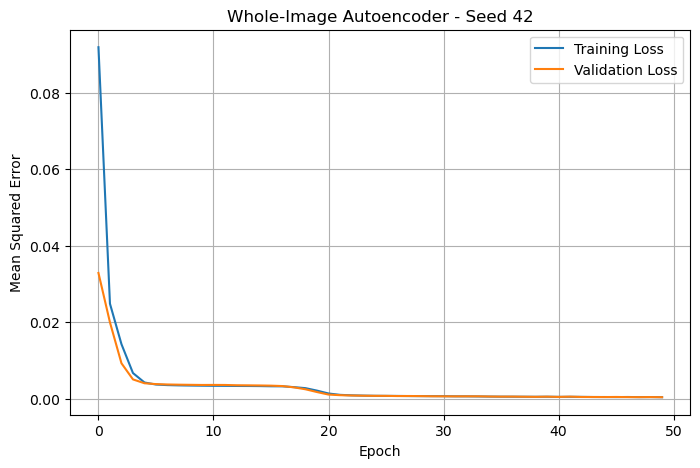

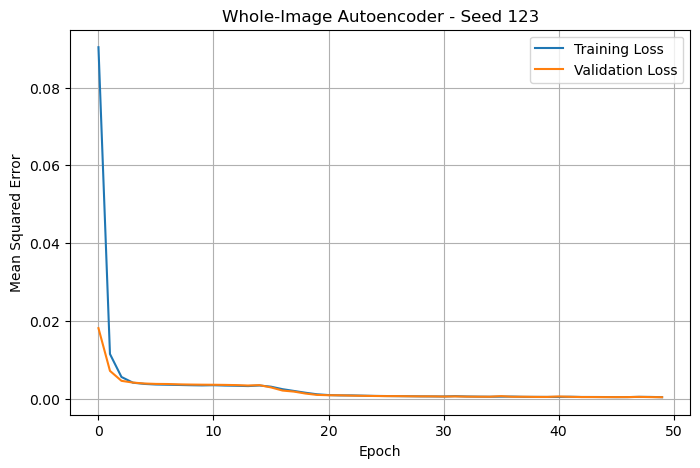

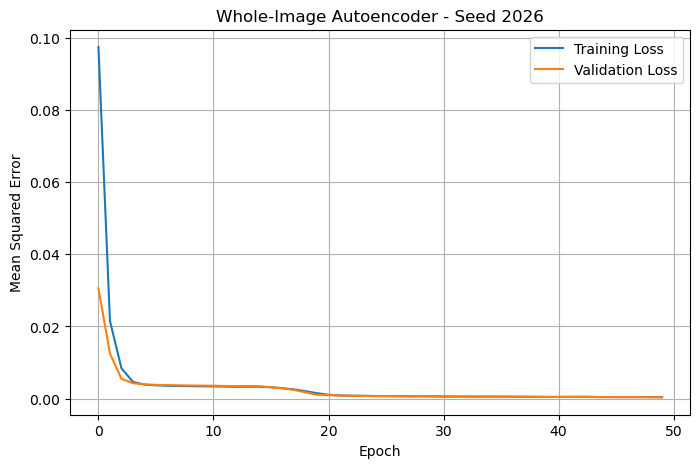

In [10]:
# Create a separate loss graph for each seed
for seed in seeds:

    plt.figure(figsize=(8, 5))

    plt.plot(
        all_results[seed]["train_losses"],
        label="Training Loss"
    )

    plt.plot(
        all_results[seed]["val_losses"],
        label="Validation Loss"
    )

    plt.xlabel("Epoch")
    plt.ylabel("Mean Squared Error")
    plt.title(f"Whole-Image Autoencoder - Seed {seed}")
    plt.legend()
    plt.grid(True)

    # Save figure
    plt.savefig(
        FIGURE_DIR / f"whole_image_training_seed_{seed}.png",
        bbox_inches="tight"
    )

    plt.show()

In [11]:
# Display results from all three seeds
for seed in seeds:

    print(
        f"Seed {seed} | "
        f"Best Epoch: {all_results[seed]['best_epoch']} | "
        f"Best Validation Loss: {all_results[seed]['best_val_loss']:.6f}"
    )

Seed 42 | Best Epoch: 50 | Best Validation Loss: 0.000395
Seed 123 | Best Epoch: 50 | Best Validation Loss: 0.000391
Seed 2026 | Best Epoch: 50 | Best Validation Loss: 0.000376


### 9. Load the Best Model

Load the saved model checkpoint from the first random seed.

The checkpoint contains the model weights from the epoch with the lowest validation loss. This model will be used to display example reconstructions.

In [13]:
# Select a seed for the reconstruction examples
selected_seed = 2026

# Initialize the model
model = ConvAutoencoder().to(device)

# Load the best saved model
model.load_state_dict(
    torch.load(
        CHECKPOINT_DIR / f"whole_image_seed_{selected_seed}.pth",
        map_location=device
    )
)

model.eval()

print("Best model loaded successfully.")
print("Selected seed:", selected_seed)
print("Best validation loss:", all_results[selected_seed]["best_val_loss"])
print("Best epoch:", all_results[selected_seed]["best_epoch"])

Best model loaded successfully.
Selected seed: 2026
Best validation loss: 0.00037622949897030475
Best epoch: 50


### 10. Original vs. Reconstructed Images

Compare original normal validation images with their reconstructed versions.

This provides a visual example of how well the autoencoder has learned to recreate normal pill images.

The reconstruction results will be used as an initial check of model performance.

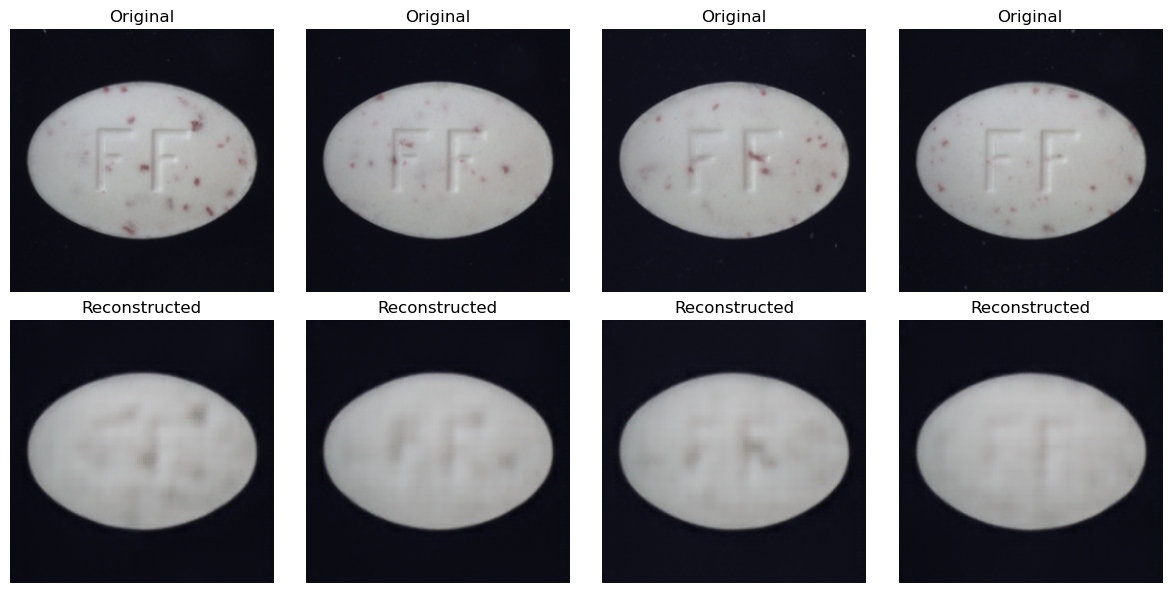

In [14]:
# Get a batch of validation images
images = next(iter(val_loader)).to(device)

# Reconstruct images
with torch.no_grad():
    reconstructed = model(images)

# Display original and reconstructed images
fig, axes = plt.subplots(2, 4, figsize=(12, 6))

for i in range(4):

    original = images[i].cpu().permute(1, 2, 0)
    rebuilt = reconstructed[i].cpu().permute(1, 2, 0)

    axes[0, i].imshow(original)
    axes[0, i].set_title("Original")
    axes[0, i].axis("off")

    axes[1, i].imshow(rebuilt)
    axes[1, i].set_title("Reconstructed")
    axes[1, i].axis("off")

plt.tight_layout()
plt.savefig(FIGURE_DIR / "whole_image_reconstructions.png")
plt.show()

### 11. Calculate Validation Anomaly Scores

Calculate anomaly scores using the normal validation images for each of the three trained models.

The reconstruction error is calculated for each pixel by comparing the original image with its reconstructed version.

The anomaly score for each image is the average of the highest 1% of pixel-level reconstruction errors.

The 95th percentile of the normal validation anomaly scores will be used as the detection threshold for each model. These thresholds will later be applied during final model evaluation in Notebook 04.

No official test images or defect masks are used in this section.

In [15]:
# Store validation anomaly scores and thresholds
score_rows = []
threshold_rows = []

# Calculate the number of pixels in the highest 1%
total_pixels = 256 * 256
top_pixels = int(np.ceil(total_pixels * 0.01))

# Calculate scores for each seed
for seed in seeds:

    print("\nCalculating validation scores for seed:", seed)

    # Load the saved model
    model = ConvAutoencoder().to(device)

    model.load_state_dict(
        torch.load(
            CHECKPOINT_DIR / f"whole_image_seed_{seed}.pth",
            map_location=device
        )
    )

    model.eval()

    # Store scores for this seed
    seed_scores = []
    image_index = 0

    # Calculate reconstruction errors
    with torch.no_grad():

        for images in val_loader:

            images = images.to(device)

            # Reconstruct images
            reconstructed = model(images)

            # Calculate pixel-level reconstruction error
            pixel_errors = torch.mean(
                (images - reconstructed) ** 2,
                dim=1
            )

            # Flatten each image's error map
            pixel_errors = pixel_errors.flatten(start_dim=1)

            # Find the highest 1% of pixel errors
            highest_errors = torch.topk(
                pixel_errors,
                k=top_pixels,
                dim=1
            ).values

            # Average the highest errors for each image
            batch_scores = highest_errors.mean(dim=1)

            # Save scores and corresponding image paths
            for score in batch_scores:

                score_value = score.item()
                seed_scores.append(score_value)

                score_rows.append({
                    "seed": seed,
                    "relative_path": val_paths[image_index],
                    "anomaly_score": score_value
                })

                image_index += 1

    # Calculate the 95th percentile threshold
    threshold = np.percentile(seed_scores, 95)

    threshold_rows.append({
        "seed": seed,
        "validation_threshold": threshold
    })

    print("Validation images scored:", len(seed_scores))
    print("95th percentile threshold:", threshold)

# Save validation anomaly scores
scores_df = pd.DataFrame(score_rows)

scores_df.to_csv(
    OUTPUT_DIR / "whole_image_validation_scores.csv",
    index=False
)

# Save thresholds
thresholds_df = pd.DataFrame(threshold_rows)

thresholds_df.to_csv(
    OUTPUT_DIR / "whole_image_validation_thresholds.csv",
    index=False
)

print("\nValidation scores and thresholds saved successfully.")


Calculating validation scores for seed: 42
Validation images scored: 53
95th percentile threshold: 0.020950520038604734

Calculating validation scores for seed: 123
Validation images scored: 53
95th percentile threshold: 0.02006178461015224

Calculating validation scores for seed: 2026
Validation images scored: 53
95th percentile threshold: 0.019900416582822798

Validation scores and thresholds saved successfully.


### 11. Summary

This notebook developed three independent whole-image convolutional autoencoders using normal pill images from the MVTec AD dataset.

The shared dataset split contained 214 training images and 53 validation images. All images were resized to 256 × 256 pixels and converted to RGB tensors.

Each model was trained using a different random seed. Early stopping was used to monitor validation loss and save the best checkpoint from each run.

Training and validation loss were recorded and visualized for all three models. Original and reconstructed validation images were also compared.

Finally, validation anomaly scores were calculated using the average of the highest 1% of pixel-level reconstruction errors. A separate 95th-percentile threshold was calculated for each model.

The model checkpoints, training figures, validation scores, and thresholds were saved for use in the final evaluation and comparison in Notebook 04.

The official test images and defect masks were not used during model training or validation threshold selection.